# PCD Assignment 03 - Segmentation and Morphological Processing

**Gradien Ridholumintu**  
**25/555306/PA/23271**

Thresholding is a simple way to separate bright nuclei from the darker background in fluorescence images. However, some nuclei may be only partly detected, while other pixels may be included by mistake. Morphological processing can change these regions, but it does not necessarily make the segmentation more accurate.

In this experiment, I use Otsu thresholding as the initial segmentation method, then apply erosion, dilation, opening, and closing to the binary masks. The results are compared with the reference masks provided by the dataset, both visually and using overlap measurements. The segmentation and morphological operations are implemented manually.

## 1. Dataset

Three images from **BBBC008v1** are used with their corresponding foreground masks. The images contain bright nuclei against a darker background. The reference masks are used only for evaluation, not for selecting thresholds or morphological parameters.

| Image | BBBC008 sample |
|---|---|
| Image 1 | A24, slice 1 |
| Image 2 | L15, slice 1 |
| Image 3 | L15, slice 6 |

The image and mask files are read from the `data/` directory.

In [22]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

image_dir = Path("data/human_ht29_colon_cancer_2_images")
mask_dir = Path("data/human_ht29_colon_cancer_2_foreground")

filenames = [
    "AS_09125_050116000001_A24f00d0_slice1_channel1.tif",
    "AS_09125_050116000001_L15f00d0_slice1_channel1.tif",
    "AS_09125_050116000001_L15f00d0_slice6_channel1.tif",
]

images = {}
references = {}

for i, filename in enumerate(filenames, 1):
    image = cv2.imread(str(image_dir / filename), cv2.IMREAD_GRAYSCALE)
    raw_mask = cv2.imread(str(mask_dir / filename), cv2.IMREAD_UNCHANGED)
    if image is None or raw_mask is None:
        raise FileNotFoundError(f"Missing image or mask: {filename}")

    reference = raw_mask > 0
    # TIFF mask polarity can depend on the image reader.
    if reference.mean() > 0.5:
        reference = ~reference

    label = f"Image {i}"
    images[label] = image
    references[label] = reference

print(f"Loaded {len(images)} image–mask pairs.")

Loaded 3 image–mask pairs.


## 2. Otsu thresholding

Otsu's method determines a threshold by maximizing the between-class variance:

$$\sigma_B^2(t) = w_0(t)w_1(t)\left[\mu_0(t)-\mu_1(t)\right]^2$$

Here, $w_0$ and $w_1$ are the class proportions, while $\mu_0$ and $\mu_1$ are their mean intensities. Pixels above the selected threshold are classified as foreground.

In [23]:
def otsu_threshold(image):
    histogram = [0] * 256
    for pixel in image.flat:
        histogram[int(pixel)] += 1

    total_pixels = image.size
    total_sum = sum(i * count for i, count in enumerate(histogram))
    background_count = 0
    background_sum = 0
    best_threshold = 0
    best_variance = -1

    for t in range(256):
        background_count += histogram[t]
        background_sum += t * histogram[t]
        foreground_count = total_pixels - background_count

        if background_count == 0 or foreground_count == 0:
            continue

        mean_background = background_sum / background_count
        mean_foreground = (total_sum - background_sum) / foreground_count
        weight_background = background_count / total_pixels
        weight_foreground = foreground_count / total_pixels
        variance = weight_background * weight_foreground * (mean_background - mean_foreground) ** 2

        if variance > best_variance:
            best_variance = variance
            best_threshold = t

    return best_threshold

thresholds = {name: otsu_threshold(image) for name, image in images.items()}
segmented = {name: image > thresholds[name] for name, image in images.items()}

for name, threshold in thresholds.items():
    print(f"{name}: T = {threshold}")

Image 1: T = 57
Image 2: T = 31
Image 3: T = 41


## 3. Morphological Operations

Morphological operations modify the shape of foreground regions using a structuring element. In this experiment, a 3×3 square kernel is used for all operations.

Erosion shrinks foreground regions, while dilation expands them. Opening combines erosion followed by dilation to remove small foreground regions. Closing applies the operations in reverse order, helping fill small holes and gaps.

All operations use Boolean masks, where `True` represents foreground pixels and `False` represents background pixels. Pixels outside the image boundaries are treated as background.

In [24]:
kernel = np.ones((3, 3), dtype=bool)

def dilation(mask, kernel):
    h, w = mask.shape
    kh, kw = kernel.shape
    padded = np.pad(mask, ((kh // 2, kh // 2), (kw // 2, kw // 2)),
                    mode="constant", constant_values=False)
    result = np.zeros_like(mask, dtype=bool)

    for y in range(kh):
        for x in range(kw):
            if kernel[y, x]:
                result |= padded[y:y+h, x:x+w]
    return result

def erosion(mask, kernel):
    h, w = mask.shape
    kh, kw = kernel.shape
    padded = np.pad(mask, ((kh // 2, kh // 2), (kw // 2, kw // 2)),
                    mode="constant", constant_values=False)
    result = np.ones_like(mask, dtype=bool)

    for y in range(kh):
        for x in range(kw):
            if kernel[y, x]:
                result &= padded[y:y+h, x:x+w]
    return result

def opening(mask, kernel):
    return dilation(erosion(mask, kernel), kernel)

def closing(mask, kernel):
    return erosion(dilation(mask, kernel), kernel)

## 4. Segmentation Results

The morphological operations are applied separately to the binary masks obtained from Otsu thresholding. Each operation uses the same initial mask and a 3×3 structuring element to keep the comparison consistent.

In addition to the four individual operations, opening followed by closing is applied to observe how combining the two operations affects the segmentation results.

In [25]:
methods = ["Otsu", "Erosion", "Dilation", "Opening", "Closing", "Opening + closing"]
results = {}

for name, mask in segmented.items():
    opened = opening(mask, kernel)
    results[name] = {
        "Otsu": mask,
        "Erosion": erosion(mask, kernel),
        "Dilation": dilation(mask, kernel),
        "Opening": opened,
        "Closing": closing(mask, kernel),
        "Opening + closing": closing(opened, kernel),
    }

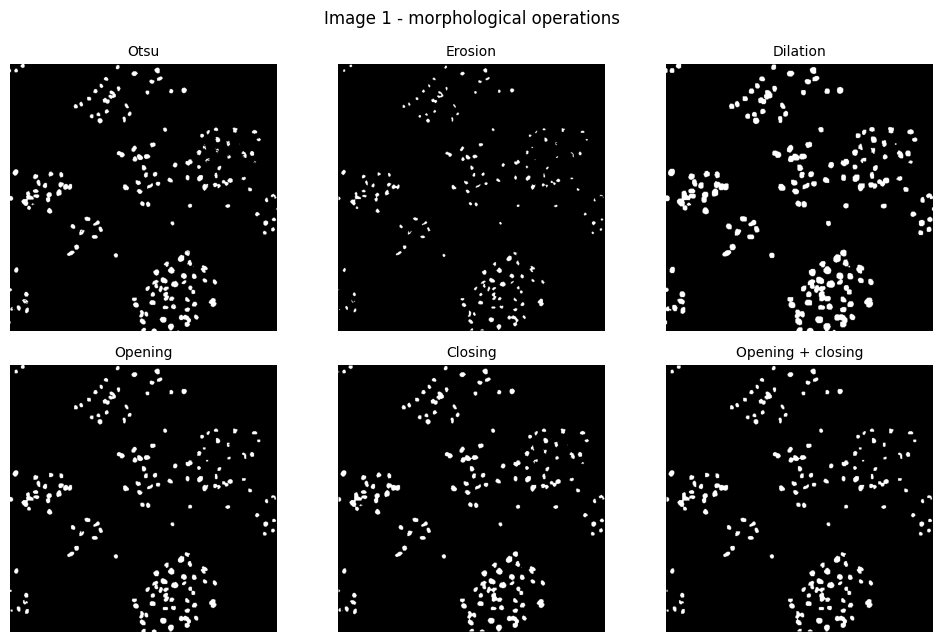

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))

for ax, method in zip(axes.flat, methods):
    ax.imshow(results["Image 1"][method], cmap="gray", vmin=0, vmax=1)
    ax.set_title(method, fontsize=10)
    ax.axis("off")

fig.suptitle("Image 1 - morphological operations", fontsize=12)
plt.tight_layout()
plt.show()

## 5. Comparison with Reference Masks

The segmentation results are evaluated by comparing each binary mask with its corresponding reference mask. Four metrics are used: Intersection over Union (IoU), Dice coefficient, precision, and recall.

IoU and Dice measure the overlap between the segmented regions and the reference mask. Precision measures how many pixels identified as foreground are correctly classified, while recall measures how many actual foreground pixels are detected.

The IoU and Dice coefficients are calculated as follows:

$$
\mathrm{IoU}=\frac{TP}{TP+FP+FN}
$$

$$
\mathrm{Dice}=\frac{2TP}{2TP+FP+FN}
$$

where \(TP\), \(FP\), and \(FN\) represent true positives, false positives, and false negatives, respectively. Higher values indicate better agreement with the reference mask.

In [27]:
def evaluate(prediction, reference):
    tp = np.count_nonzero(prediction & reference)
    fp = np.count_nonzero(prediction & ~reference)
    fn = np.count_nonzero(~prediction & reference)

    return {
        "IoU": tp / (tp + fp + fn),
        "Dice": 2 * tp / (2 * tp + fp + fn),
        "Precision": tp / (tp + fp),
        "Recall": tp / (tp + fn),
    }

rows = []
for name in images:
    for method, mask in results[name].items():
        rows.append({"Image": name, "Method": method,
                     **evaluate(mask, references[name])})

scores = pd.DataFrame(rows)
per_image = scores.pivot(index="Image", columns="Method", values="IoU")[methods]
averages = scores.groupby("Method")[["IoU", "Dice", "Precision", "Recall"]].mean().loc[methods]

print("IoU for each image")
display(per_image.round(3))
print("Average scores")
display(averages.round(3))

IoU for each image


Method,Otsu,Erosion,Dilation,Opening,Closing,Opening + closing
Image,,,,,,
Image 1,0.816,0.405,0.706,0.783,0.813,0.778
Image 2,0.755,0.493,0.852,0.725,0.764,0.724
Image 3,0.480,0.287,0.632,0.468,0.485,0.469


Average scores


,IoU,Dice,Precision,Recall
Method,,,,
Otsu,0.684,0.803,0.984,0.688
Erosion,0.395,0.561,0.997,0.395
Dilation,0.730,0.841,0.835,0.866
Opening,0.659,0.786,0.990,0.661
Closing,0.688,0.806,0.981,0.694
Opening + closing,0.657,0.785,0.987,0.661


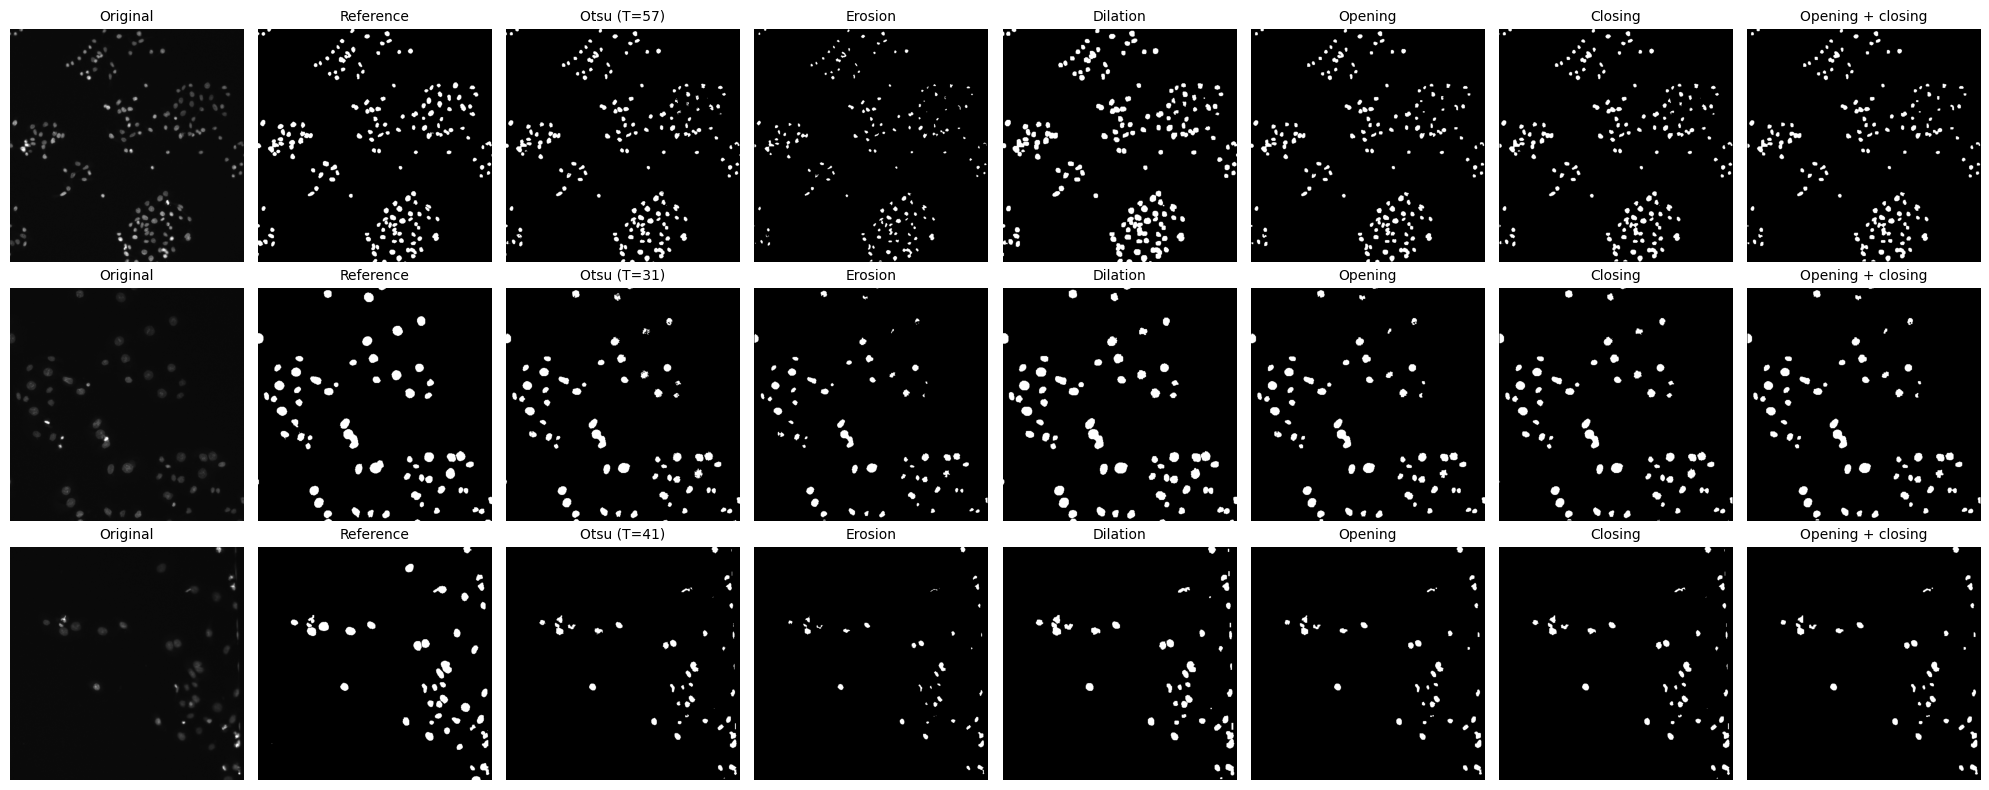

In [28]:
methods = ["Otsu", "Erosion", "Dilation", "Opening", "Closing", "Opening + closing"]

fig, axes = plt.subplots(len(images), 8, figsize=(20, 8))

for row, name in enumerate(images):
    panels = [images[name], references[name]]
    panels += [results[name][method] for method in methods]

    titles = [
        "Original",
        "Reference",
        f"Otsu (T={thresholds[name]})",
        "Erosion",
        "Dilation",
        "Opening",
        "Closing",
        "Opening + closing"
    ]

    for col, (panel, title) in enumerate(zip(panels, titles)):
        axes[row, col].imshow(
            panel,
            cmap="gray",
            vmin=0,
            vmax=255 if col == 0 else 1
        )
        axes[row, col].set_title(title, fontsize=10)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(name, fontsize=11)

plt.tight_layout()
plt.show()

## 6. Discussion and conclusion

Otsu thresholding produced a mean IoU of **0.684**. Dilation achieved the highest mean IoU (**0.730**), mainly by recovering foreground pixels that had been missed during thresholding. Its mean recall increased from **0.688** to **0.866**, although precision decreased from **0.984** to **0.835**.

The improvement was not consistent across all images. Dilation reduced the IoU of Image 1 from **0.816** to **0.706**, but improved Images 2 and 3 from **0.755** to **0.852** and **0.480** to **0.632**, respectively. Erosion performed worst (mean IoU **0.395**) because it removed too much foreground. Opening (**0.659**) and opening followed by closing (**0.657**) were also below the baseline. Closing alone produced only a small change (**0.688**).

Under these settings, dilation gave the best average result, but morphological processing did not improve every segmentation. The experiment is limited to three images and a single 3×3 structuring element.